# Machine Learning for Predicting Sediment Particle-Size Distribution


## 1. Uploading the CSV files

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

TABLE1_PATH = '/content/drive/MyDrive/Table1_LISST_SSC_ADCP.csv'
TABLE2_PATH = '/content/drive/MyDrive/Table2_LISST_PSD1.csv'

for path in [TABLE1_PATH, TABLE2_PATH]:
    if not Path(path).exists():
        raise FileNotFoundError(f'Missing {path}. Upload both CSV files in the previous cell.')

table1 = pd.read_csv(TABLE1_PATH)
table2 = pd.read_csv(TABLE2_PATH)
print('Table 1:', table1.shape)
print('Table 2 before removing empty rows:', table2.shape)
table2 = table2.dropna(how='all').copy()
print('Table 2 after removing empty rows:', table2.shape)
display(table1.head(2))
display(table2.head(2))

Table 1: (136, 34)
Table 2 before removing empty rows: (280, 41)
Table 2 after removing empty rows: (136, 41)


,Site,Latitude,Longitude,Date,Filename_LISST,Start_time_LISST,End_time_LISST,Start_sample_LISST,End_sample_LISST,Total_samples_LISST,...,Pct_fines_phys_sample,Comment_phys_sample,ADCP_type,ADCP_filename,Start_time_ADCP,End_time_ADCP,Total_samples_ADCP,Velocity_mean_ADCP,Stdev_velocity_ADCP,Depth_ADCP
0,"New River at Whitethorne, VA",37.199,-80.562,6/12/2019,newriverWhitethrn1_12June19,14:33:38,14:35:14,3,96,94,...,na,na,SonTek_M9,20190612143135r,14:33:07,14:51:36,1110,0.9,0.14,0.31
1,"New River at Whitethorne, VA",37.199,-80.562,6/12/2019,newriverWhitethrn1_12June19,14:35:34,14:37:27,115,224,110,...,na,na,SonTek_M10,20190612143135r,14:33:07,14:51:36,1109,0.87,0.14,0.57


,Site,Date,Filename_LISST,Start_time_LISST,End_time_LISST,Conc_1_to_1.47um,Conc_1.48-1.74um,Conc_1.75_to_2.05um,Conc_2.06_to_2.42um,Conc_2.43_to_2.86um,...,Conc_92.6_to_109um,Conc_110_to_128um,Conc_129_to_152um,Conc_153_to_179um,Conc_180_to_211um,Conc_212_to_250um,Conc_251_to_297um,Conc_298_to_353um,Conc_354_to_420um,Conc_421_to_500um
0,"New River at Whitethorne, VA",6/12/2019,newriverWhitethrn1_12June19,14:33:38,14:35:14,0.0,0.0,0.000571,0.012102,0.165023,...,0.824128,0.313891,0.088427,0.018179,0.002698,0.000282,0.000020,0.000000,0.0,0.0
1,"New River at Whitethorne, VA",6/12/2019,newriverWhitethrn1_12June19,14:35:34,14:37:27,0.0,0.0,0.000571,0.012135,0.167993,...,0.654420,0.225154,0.056664,0.011276,0.002030,0.000333,0.000043,0.000005,0.0,0.0


## 2. Merging the tables

In [3]:
merge_keys = ['Site', 'Date', 'Filename_LISST', 'Start_time_LISST', 'End_time_LISST']
missing_keys = [c for c in merge_keys if c not in table1.columns or c not in table2.columns]
if missing_keys:
    raise ValueError(f'Merge key(s) missing: {missing_keys}')

merged_data = pd.merge(
    table1, table2, on=merge_keys, how='inner',
    validate='one_to_one', suffixes=('_table1', '_table2')
)
print('Merged shape:', merged_data.shape)
print('Duplicate merge keys:', merged_data.duplicated(subset=merge_keys).sum())
display(merged_data.head())
merged_data.to_csv('merged_sediment_data.csv', index=False)
print('Saved merged_sediment_data.csv')

Merged shape: (136, 70)
Duplicate merge keys: 0


,Site,Latitude,Longitude,Date,Filename_LISST,Start_time_LISST,End_time_LISST,Start_sample_LISST,End_sample_LISST,Total_samples_LISST,...,Conc_92.6_to_109um,Conc_110_to_128um,Conc_129_to_152um,Conc_153_to_179um,Conc_180_to_211um,Conc_212_to_250um,Conc_251_to_297um,Conc_298_to_353um,Conc_354_to_420um,Conc_421_to_500um
0,"New River at Whitethorne, VA",37.199,-80.562,6/12/2019,newriverWhitethrn1_12June19,14:33:38,14:35:14,3,96,94,...,0.824128,0.313891,0.088427,0.018179,0.002698,0.000282,0.000020,0.000000,0.0,0.0
1,"New River at Whitethorne, VA",37.199,-80.562,6/12/2019,newriverWhitethrn1_12June19,14:35:34,14:37:27,115,224,110,...,0.654420,0.225154,0.056664,0.011276,0.002030,0.000333,0.000043,0.000005,0.0,0.0
2,"New River at Whitethorne, VA",37.199,-80.562,6/12/2019,newriverWhitethrn1_12June19,14:37:45,14:39:28,241,340,100,...,0.582781,0.184355,0.040001,0.006021,0.000628,0.000052,0.000005,0.000000,0.0,0.0
3,"New River at Whitethorne, VA",37.199,-80.562,6/12/2019,newriverWhitethrn1_12June19,14:39:50,14:41:25,361,453,93,...,0.748965,0.274554,0.075697,0.016323,0.002852,0.000388,0.000045,0.000004,0.0,0.0
4,"New River at Whitethorne, VA",37.199,-80.562,6/12/2019,newriverWhitethrn1_12June19,14:42:40,14:44:46,523,646,124,...,0.711510,0.260981,0.072974,0.016307,0.003081,0.000505,0.000073,0.000007,0.0,0.0


Saved merged_sediment_data.csv


## 3. Defining features and targets


In [4]:
features = [
    'Depth_LISST',
    'Velocity_LISST',
    'Water_temp_LISST',
    'Stdev_velocity_LISST',
    'Optical_transmission_LISST',
    'Beam_attenuation_LISST'
]
target_columns = [
    c for c in merged_data.columns
    if c.startswith('Conc_') and c.endswith('um')
]

missing = [c for c in features + target_columns if c not in merged_data.columns]
if missing:
    raise ValueError(f'Required columns not found: {missing}')
if len(target_columns) != 36:
    print(f'Warning: expected 36 size-bin targets, found {len(target_columns)}. Check the column names.')

# Convert selected columns to numeric and remove rows with invalid values in selected fields.
model_data = merged_data[features + target_columns].copy()
for c in features + target_columns:
    model_data[c] = pd.to_numeric(model_data[c], errors='coerce')
model_data = model_data.replace([np.inf, -np.inf], np.nan).dropna(subset=features + target_columns)
X = model_data[features]
y = model_data[target_columns]
print('Usable observations:', len(model_data))
print('Input shape:', X.shape)
print('Target shape:', y.shape)
print('Missing selected values:', int(model_data.isna().sum().sum()))
display(model_data.head())

Usable observations: 136
Input shape: (136, 6)
Target shape: (136, 36)
Missing selected values: 0


,Depth_LISST,Velocity_LISST,Water_temp_LISST,Stdev_velocity_LISST,Optical_transmission_LISST,Beam_attenuation_LISST,Conc_1_to_1.47um,Conc_1.48-1.74um,Conc_1.75_to_2.05um,Conc_2.06_to_2.42um,...,Conc_92.6_to_109um,Conc_110_to_128um,Conc_129_to_152um,Conc_153_to_179um,Conc_180_to_211um,Conc_212_to_250um,Conc_251_to_297um,Conc_298_to_353um,Conc_354_to_420um,Conc_421_to_500um
0,0.31,1.19,20.1,0.09,97.32,9.06,0.0,0.0,0.000571,0.012102,...,0.824128,0.313891,0.088427,0.018179,0.002698,0.000282,0.000020,0.000000,0.0,0.0
1,0.57,1.23,20.1,0.07,97.29,9.15,0.0,0.0,0.000571,0.012135,...,0.654420,0.225154,0.056664,0.011276,0.002030,0.000333,0.000043,0.000005,0.0,0.0
2,0.91,1.02,20.1,0.08,97.25,9.31,0.0,0.0,0.000596,0.012695,...,0.582781,0.184355,0.040001,0.006021,0.000628,0.000052,0.000005,0.000000,0.0,0.0
3,1.22,0.91,20.1,0.10,97.22,9.39,0.0,0.0,0.000594,0.012505,...,0.748965,0.274554,0.075697,0.016323,0.002852,0.000388,0.000045,0.000004,0.0,0.0
4,1.48,1.00,20.1,0.14,97.23,9.38,0.0,0.0,0.000563,0.012387,...,0.711510,0.260981,0.072974,0.016307,0.003081,0.000505,0.000073,0.000007,0.0,0.0


## 4. Explore the particle-size distribution

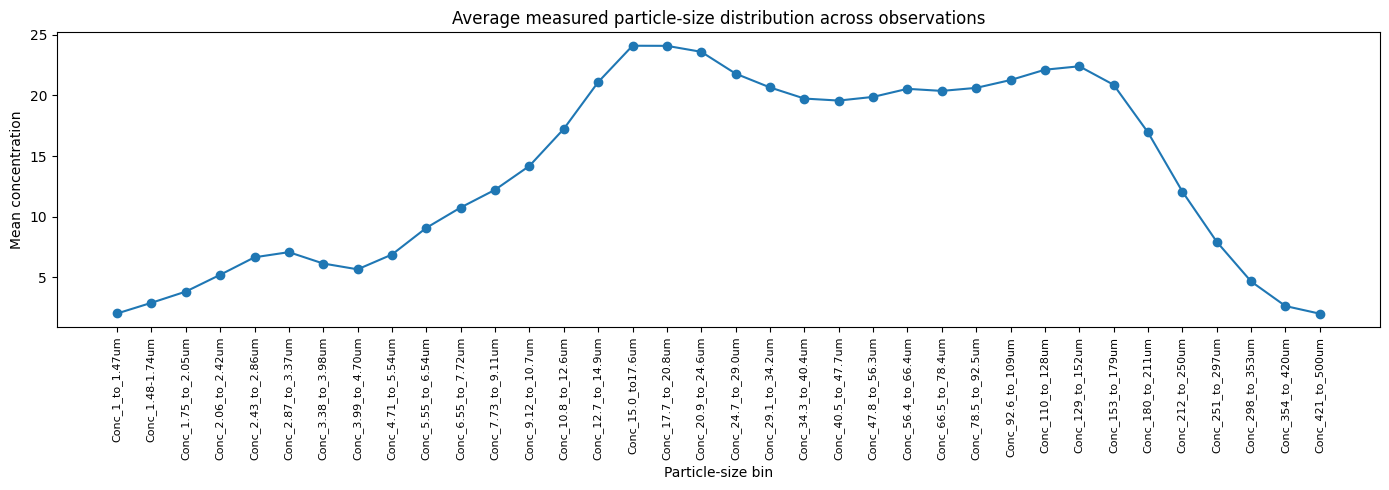

In [5]:
mean_concentration = y.mean(axis=0)
plt.figure(figsize=(14, 5))
plt.plot(range(len(target_columns)), mean_concentration.values, marker='o')
plt.xticks(range(len(target_columns)), target_columns, rotation=90, fontsize=8)
plt.xlabel('Particle-size bin')
plt.ylabel('Mean concentration')
plt.title('Average measured particle-size distribution across observations')
plt.tight_layout()
plt.show()

## 5. Split into training and test sets


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Training samples:', len(X_train))
print('Testing samples:', len(X_test))

Training samples: 108
Testing samples: 28


## 6. Train Random Forest and SVR


In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor
from sklearn.svm import SVR

rf_model = RandomForestRegressor(
    n_estimators=200, max_depth=10, min_samples_leaf=2,
    random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)
print('Random Forest training complete.')

svr_model = make_pipeline(
    StandardScaler(),
    MultiOutputRegressor(SVR(kernel='rbf', C=10, epsilon=0.1))
)
svr_model.fit(X_train, y_train)
print('SVR training complete.')

Random Forest training complete.
SVR training complete.


## 7. Evaluate the models


In [8]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def overall_metrics(name, model, X_eval, y_eval):
    pred = model.predict(X_eval)
    return {
        'Model': name,
        'R2_uniform_average': r2_score(y_eval, pred, multioutput='uniform_average'),
        'MAE_all_values': mean_absolute_error(y_eval, pred),
        'RMSE_all_values': float(np.sqrt(mean_squared_error(y_eval, pred)))
    }, pred

rf_metrics, y_pred_rf = overall_metrics('Random Forest', rf_model, X_test, y_test)
svr_metrics, y_pred_svr = overall_metrics('SVR', svr_model, X_test, y_test)
metrics_df = pd.DataFrame([rf_metrics, svr_metrics])
display(metrics_df.round(5))
metrics_df.to_csv('model_metrics.csv', index=False)
print('Saved model_metrics.csv')

,Model,R2_uniform_average,MAE_all_values,RMSE_all_values
0,Random Forest,0.85104,5.78599,14.36903
1,SVR,0.31625,14.82693,41.15762


Saved model_metrics.csv


## 8. Per-bin evaluation


In [9]:
per_bin_rows = []
y_test_np = np.asarray(y_test)
for i, target in enumerate(target_columns):
    per_bin_rows.append({
        'target_bin': target,
        'RF_R2': r2_score(y_test_np[:, i], y_pred_rf[:, i]) if np.unique(y_test_np[:, i]).size > 1 else np.nan,
        'RF_MAE': mean_absolute_error(y_test_np[:, i], y_pred_rf[:, i]),
        'SVR_R2': r2_score(y_test_np[:, i], y_pred_svr[:, i]) if np.unique(y_test_np[:, i]).size > 1 else np.nan,
        'SVR_MAE': mean_absolute_error(y_test_np[:, i], y_pred_svr[:, i])
    })
per_bin_metrics = pd.DataFrame(per_bin_rows)
display(per_bin_metrics.head(10).round(5))
per_bin_metrics.to_csv('per_bin_metrics.csv', index=False)

,target_bin,RF_R2,RF_MAE,SVR_R2,SVR_MAE
0,Conc_1_to_1.47um,0.82102,0.86998,0.85253,0.85777
1,Conc_1.48-1.74um,0.91149,0.99814,0.90283,1.03256
2,Conc_1.75_to_2.05um,0.93397,1.23674,0.95842,1.00874
3,Conc_2.06_to_2.42um,0.93107,1.69760,0.89876,1.80326
4,Conc_2.43_to_2.86um,0.90699,2.24942,0.80062,2.90033
5,Conc_2.87_to_3.37um,0.89863,2.25447,0.75411,3.04298
6,Conc_3.38_to_3.98um,0.93229,1.69327,0.75296,2.54330
7,Conc_3.99_to_4.70um,0.96951,1.19132,0.72126,2.75830
8,Conc_4.71_to_5.54um,0.97764,1.39030,0.64153,3.77085
9,Conc_5.55_to_6.54um,0.97640,2.22398,0.53081,6.59791


## 9. Plot an example measured distribution vs prediction


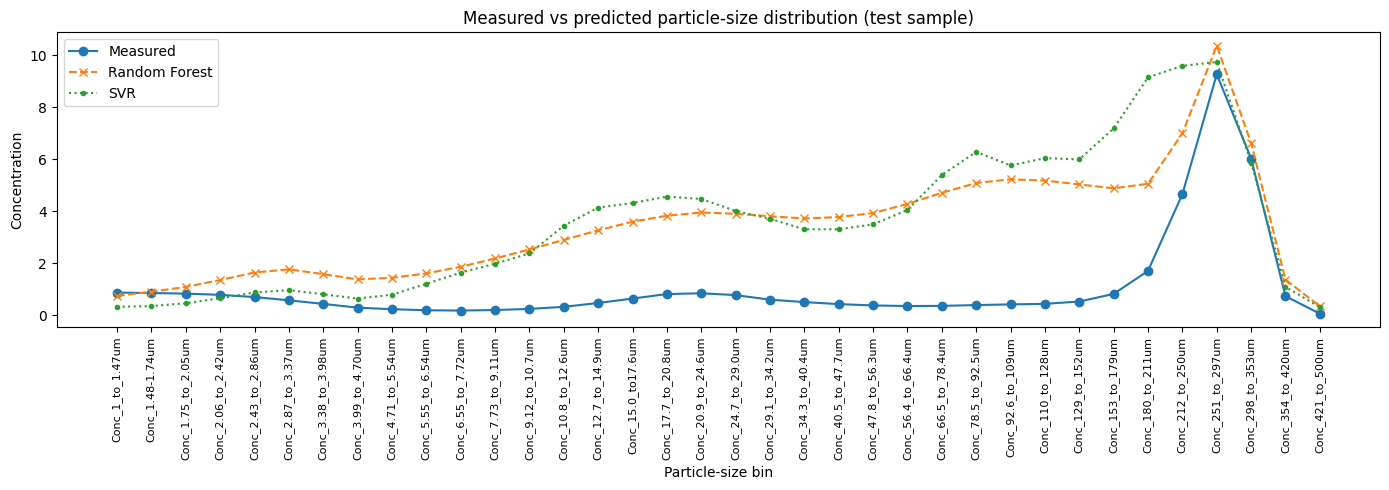

In [10]:
sample_idx = 0
actual = y_test.iloc[sample_idx].to_numpy()

plt.figure(figsize=(14, 5))
plt.plot(range(len(target_columns)), actual, marker='o', label='Measured')
plt.plot(range(len(target_columns)), y_pred_rf[sample_idx], marker='x', linestyle='--', label='Random Forest')
plt.plot(range(len(target_columns)), y_pred_svr[sample_idx], marker='.', linestyle=':', label='SVR')
plt.xticks(range(len(target_columns)), target_columns, rotation=90, fontsize=8)
plt.xlabel('Particle-size bin')
plt.ylabel('Concentration')
plt.title('Measured vs predicted particle-size distribution (test sample)')
plt.legend()
plt.tight_layout()
plt.show()

## 10. Random Forest feature importance


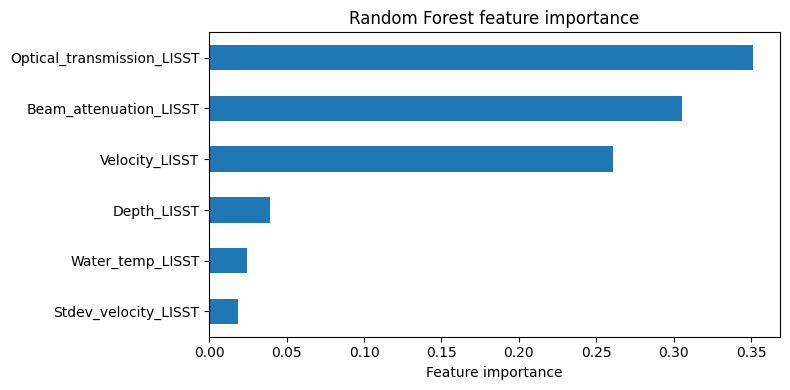

,importance
Optical_transmission_LISST,0.351138
Beam_attenuation_LISST,0.305703
Velocity_LISST,0.260611
Depth_LISST,0.039322
Water_temp_LISST,0.024654
Stdev_velocity_LISST,0.018573


In [11]:
importance = pd.Series(rf_model.feature_importances_, index=features).sort_values()
plt.figure(figsize=(8, 4))
importance.plot(kind='barh')
plt.xlabel('Feature importance')
plt.title('Random Forest feature importance')
plt.tight_layout()
plt.show()
display(importance.sort_values(ascending=False).rename('importance').to_frame())

## 11. Save model and predictions


In [12]:
import joblib
joblib.dump(rf_model, 'sediment_random_forest.joblib')
joblib.dump(svr_model, 'sediment_svr.joblib')

predictions_df = pd.DataFrame(y_pred_rf, columns=[f'RF_pred_{c}' for c in target_columns])
actual_df = y_test.reset_index(drop=True).add_prefix('actual_')
comparison_df = pd.concat([actual_df, predictions_df.reset_index(drop=True)], axis=1)
comparison_df.to_csv('test_predictions_random_forest.csv', index=False)

print('Saved: sediment_random_forest.joblib')
print('Saved: sediment_svr.joblib')
print('Saved: test_predictions_random_forest.csv')
print('Saved: model_metrics.csv and per_bin_metrics.csv')

Saved: sediment_random_forest.joblib
Saved: sediment_svr.joblib
Saved: test_predictions_random_forest.csv
Saved: model_metrics.csv and per_bin_metrics.csv


## 12. Downloading outputs

In [13]:
from google.colab import files
files.download('merged_sediment_data.csv')
files.download('model_metrics.csv')
files.download('per_bin_metrics.csv')
files.download('test_predictions_random_forest.csv')
# Optional model downloads:
# files.download('sediment_random_forest.joblib')
# files.download('sediment_svr.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:

import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Predict the mean concentration of each bin from the training set
baseline_predictions = np.tile(
    y_train.mean(axis=0).to_numpy(),
    (len(y_test), 1)
)

# Evaluate the baseline
baseline_metrics = {
    "Model": "Mean Baseline",
    "R2_uniform_average": r2_score(
        y_test, baseline_predictions, multioutput="uniform_average"
    ),
    "MAE_all_values": mean_absolute_error(
        y_test, baseline_predictions
    ),
    "RMSE_all_values": np.sqrt(
        mean_squared_error(y_test, baseline_predictions)
    )
}

# Compare with your existing results
comparison = pd.concat(
    [metrics_df, pd.DataFrame([baseline_metrics])],
    ignore_index=True
)

display(comparison.round(5))
comparison.to_csv("model_comparison_with_baseline.csv", index=False)
print("Saved model_comparison_with_baseline.csv")


,Model,R2_uniform_average,MAE_all_values,RMSE_all_values
0,Random Forest,0.85104,5.78599,14.36903
1,SVR,0.31625,14.82693,41.15762
2,Mean Baseline,-0.04965,20.40691,45.80784


Saved model_comparison_with_baseline.csv


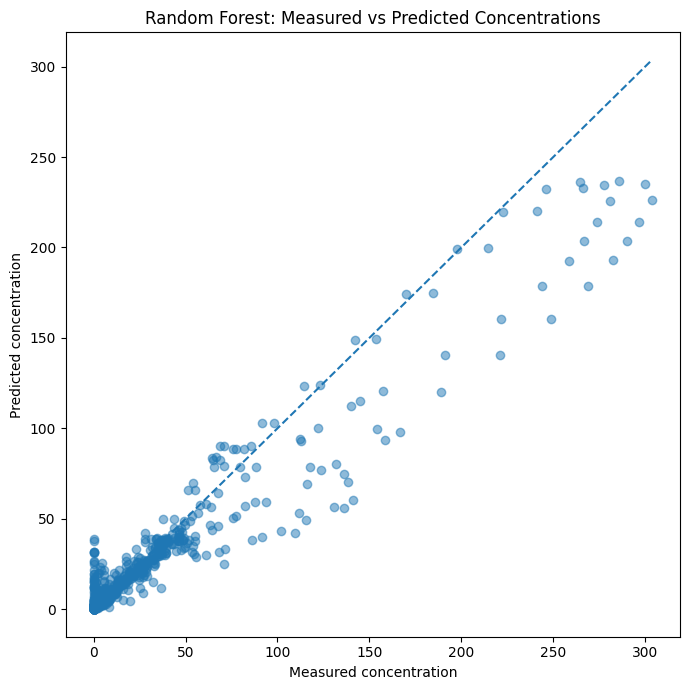

In [17]:

import matplotlib.pyplot as plt
import numpy as np

# Flatten the 36-bin test targets and predictions for visualization
actual_values = np.asarray(y_test).ravel()
predicted_values = np.asarray(y_pred_rf).ravel()

plt.figure(figsize=(7, 7))
plt.scatter(actual_values, predicted_values, alpha=0.5)

limit = max(actual_values.max(), predicted_values.max())
plt.plot([0, limit], [0, limit], linestyle="--")

plt.xlabel("Measured concentration")
plt.ylabel("Predicted concentration")
plt.title("Random Forest: Measured vs Predicted Concentrations")
plt.tight_layout()
plt.show()
